# Linear Regression Health Costs Calculator

**Author: cear12**

A solution to the [freeCodeCamp project](https://www.freecodecamp.org/learn/machine-learning-with-python/machine-learning-with-python-projects/linear-regression-health-costs-calculator).
Predict insurance expenses from age, sex, BMI, number of children, smoking status and region.
The acceptance criterion is a **test mean absolute error below 3,500 expense units**.

Run all cells in Google Colab or Jupyter. This notebook downloads its data and does not
import local project files. A Keras regression network learns nonlinear relationships
among the attributes. The original final evaluation cell is preserved unchanged.

In [1]:
import os
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("MPLCONFIGDIR", str(Path(".cache/matplotlib").resolve()))
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)

import hashlib
import json
import urllib.request
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
tf.config.threading.set_intra_op_parallelism_threads(min(4, os.cpu_count() or 1))
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.keras.utils.set_random_seed(SEED)
CACHE = Path(".cache")
ARTIFACTS = Path("artifacts")
CACHE.mkdir(exist_ok=True)
ARTIFACTS.mkdir(exist_ok=True)
print(f"TensorFlow {tf.__version__}; seed {SEED}")

TensorFlow 2.20.0; seed 42


## 1. Load the official dataset

Verify the source CSV's SHA-256 checksum. The original CDN has an official GitHub
mirror as a fallback. The dataset has 1,338 rows, six input attributes and an
`expenses` target. The target is never included in the model's input features.

In [2]:
DATA_SHA256 = "6f9588de10a0a8a1f2d1356468f2d21e62ab20b141f316d882fc9b4aa3f29938"
DATA_URLS = (
    "https://cdn.freecodecamp.org/project-data/health-costs/insurance.csv",
    "https://raw.githubusercontent.com/freeCodeCamp/cdn/main/build/project-data/health-costs/insurance.csv",
)


def prepare_data(cache=CACHE):
    target = Path(cache) / "insurance.csv"
    target.parent.mkdir(parents=True, exist_ok=True)
    if target.exists() and hashlib.sha256(target.read_bytes()).hexdigest() == DATA_SHA256:
        return target
    errors = []
    for url in DATA_URLS:
        try:
            request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(request, timeout=60) as response:
                content = response.read()
            if hashlib.sha256(content).hexdigest() != DATA_SHA256:
                raise ValueError("Dataset checksum mismatch")
            target.write_bytes(content)
            return target
        except (OSError, ValueError) as error:
            errors.append(f"{url}: {error}")
    raise RuntimeError("Dataset download failed:\n" + "\n".join(errors))

In [3]:
dataset = pd.read_csv(prepare_data())
assert dataset.shape == (1338, 7) and not dataset.isna().any().any()
print(f"Dataset: {len(dataset):,} rows")
dataset.tail()

Dataset: 1,338 rows


,age,sex,bmi,children,smoker,region,expenses
1333,50,male,31.0,3,no,northwest,10600.55
1334,18,female,31.9,0,no,northeast,2205.98
1335,18,female,36.9,0,no,southeast,1629.83
1336,21,female,25.8,0,no,southwest,2007.95
1337,61,female,29.1,0,yes,northwest,29141.36


## 2. Separate training and test rows

Use a reproducible 80% / 20% split. Reserve 20% of the training pool for validation;
test rows are untouched until the final check. Training, validation and test indices
are disjoint. Validation loss controls early stopping and checkpoint selection.

In [4]:
def split_dataset(frame, seed=42):
    training = frame.sample(frac=0.8, random_state=seed)
    testing = frame.drop(training.index)
    validation = training.sample(frac=0.2, random_state=seed + 1)
    fitting = training.drop(validation.index)
    return training.copy(), fitting.copy(), validation.copy(), testing.copy()

In [5]:
training_rows, fitting_rows, validation_rows, testing_rows = split_dataset(dataset, SEED)
assert set(fitting_rows.index).isdisjoint(validation_rows.index)
assert set(training_rows.index).isdisjoint(testing_rows.index)
print(f"Training pool: {len(training_rows)} = {len(fitting_rows)} fit + {len(validation_rows)} validation")
print(f"Held-out test: {len(testing_rows)}")

Training pool: 1070 = 856 fit + 214 validation
Held-out test: 268


## 3. Encode attributes and extract labels

One-hot encode the three categorical attributes with a fixed domain vocabulary.
Keep numeric attributes as float32. Each split has exactly the same ordered columns.
Unknown categories, missing values and invalid numeric inputs raise clear errors.
Input normalization is learned later from the fitting subset alone.

In [6]:
NUMERIC = ("age", "bmi", "children")
CATEGORIES = {
    "sex": ("female", "male"),
    "smoker": ("no", "yes"),
    "region": ("northeast", "northwest", "southeast", "southwest"),
}
FEATURES = list(NUMERIC) + list(CATEGORIES)


def encode_features(frame):
    if set(frame.columns) != set(FEATURES):
        raise ValueError(f"Expected exactly these six input attributes: {FEATURES}")
    values = frame.loc[:, FEATURES].copy()
    if values.isna().any().any():
        raise ValueError("Input attributes must not contain missing values")
    for name in NUMERIC:
        values[name] = pd.to_numeric(values[name], errors="raise")
        numeric = values[name].to_numpy(dtype=float)
        if not np.isfinite(numeric).all() or (numeric < 0).any():
            raise ValueError(f"{name} must contain finite, nonnegative numbers")
    for name, categories in CATEGORIES.items():
        if not values[name].isin(categories).all():
            raise ValueError(f"Unknown {name}; expected one of {list(categories)}")
        values[name] = pd.Categorical(values[name], categories=categories)
    return pd.get_dummies(values, columns=list(CATEGORIES), dtype=np.float32).astype(np.float32)

In [7]:
train_dataset = training_rows.copy()
test_dataset = testing_rows.copy()
train_labels = train_dataset.pop("expenses").astype(np.float32)
test_labels = test_dataset.pop("expenses").astype(np.float32)
train_dataset = encode_features(train_dataset)
test_dataset = encode_features(test_dataset)
fit_dataset = train_dataset.loc[fitting_rows.index]
fit_labels = train_labels.loc[fitting_rows.index]
val_dataset = train_dataset.loc[validation_rows.index]
val_labels = train_labels.loc[validation_rows.index]
assert train_dataset.columns.equals(test_dataset.columns)
assert "expenses" not in train_dataset.columns
print(f"Numeric input columns: {len(train_dataset.columns)}")
train_dataset.head()

Numeric input columns: 11


,age,bmi,children,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
764,45.0,25.200001,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
887,36.0,30.000000,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
890,64.0,26.900000,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1293,46.0,25.700001,3.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
259,19.0,31.900000,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0


## 4. Build the regression model

Normalize using fitting-row statistics, then use two 64-unit dense layers.
A softplus output keeps expense estimates nonnegative. Its output is rescaled inside
the model to the original expense units, so labels, loss, MAE, predictions and the
official acceptance check all use the same units.

Optimize mean absolute error. This directly matches the assignment's metric and
limits the influence of unusually large residuals compared with squared error.

In [8]:
def build_model(fitting_features):
    features = np.asarray(fitting_features, dtype=np.float32)
    normalizer = layers.Normalization(axis=-1, name="input_normalization")
    normalizer.adapt(features)
    model = keras.Sequential([
        layers.Input(shape=(features.shape[1],)),
        normalizer,
        layers.Dense(64, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(1, activation="softplus"),
        layers.Rescaling(10000.0, name="expense_units"),
    ], name="health_cost_regression")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.003),
                  loss=keras.losses.MeanAbsoluteError(),
                  metrics=[keras.metrics.MeanAbsoluteError(name="mae"),
                           keras.metrics.MeanSquaredError(name="mse")])
    return model

In [9]:
model = build_model(fit_dataset)
model.summary()

Model: "health_cost_regression"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_normalization             │ (None, 11)             │            23 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ expense_units (Rescaling)       │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,016 (19.60 KB)

 Trainable params: 4,993 (19.50 KB)

 Non-trainable params: 23 (96.00 B)

## 5. Train and select the checkpoint using validation MAE

Train for up to 500 epochs, lowering the learning rate when validation loss stalls.
Stop early after 50 epochs without improvement and restore the best validation-loss
checkpoint. The test set is not used for model selection.

In [10]:
def batches(features, labels, shuffle=False):
    data = tf.data.Dataset.from_tensor_slices(
        (np.asarray(features, dtype=np.float32), np.asarray(labels, dtype=np.float32)))
    if shuffle:
        data = data.shuffle(len(features), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    return data.batch(32).with_options(options).prefetch(1)

callbacks = [
    keras.callbacks.ModelCheckpoint(str(ARTIFACTS / "health_costs.keras"),
                                    monitor="val_loss", save_best_only=True),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=50, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=15, factor=0.5, min_lr=1e-5),
]
history = model.fit(batches(fit_dataset, fit_labels, shuffle=True),
                    validation_data=batches(val_dataset, val_labels),
                    epochs=500, callbacks=callbacks, shuffle=False, verbose=0)
model = keras.models.load_model(ARTIFACTS / "health_costs.keras")
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"Epochs completed: {len(history.history['loss'])}; best epoch: {best_epoch}")
print(f"Best validation MAE: {min(history.history['val_mae']):,.2f} expenses")

Epochs completed: 147; best epoch: 97
Best validation MAE: 1,512.40 expenses


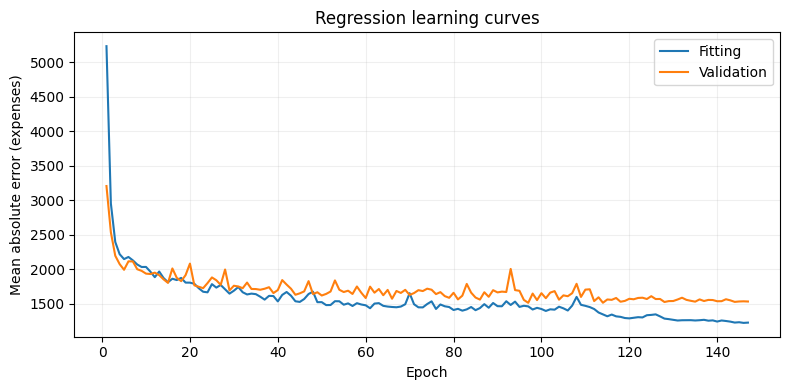

In [11]:
epoch_numbers = range(1, len(history.history["loss"]) + 1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(epoch_numbers, history.history["mae"], label="Fitting")
ax.plot(epoch_numbers, history.history["val_mae"], label="Validation")
ax.set(xlabel="Epoch", ylabel="Mean absolute error (expenses)", title="Regression learning curves")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(ARTIFACTS / "learning_curves.png", dpi=120)
plt.show()
plt.close(fig)

## 6. Run the original acceptance check

The following cell is unchanged from the official starter. It evaluates the final model
on the held-out 20% of rows, checks MAE below 3,500 and plots actual versus predicted expenses.

9/9 - 0s - 12ms/step - loss: 1785.4470 - mae: 1785.4471 - mse: 26860350.0000


Testing set Mean Abs Error: 1785.45 expenses
You passed the challenge. Great job!
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


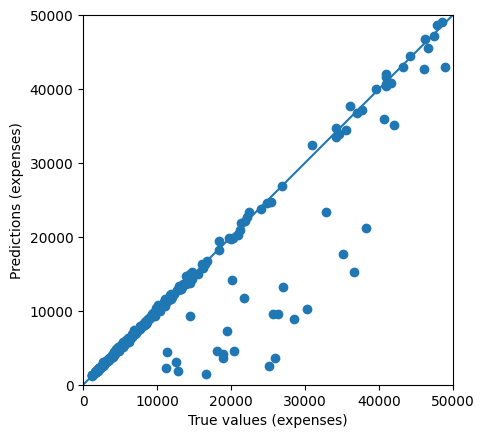

In [12]:
# RUN THIS CELL TO TEST YOUR MODEL. DO NOT MODIFY CONTENTS.
# Test model by checking how well the model generalizes using the test set.
loss, mae, mse = model.evaluate(test_dataset, test_labels, verbose=2)

print("Testing set Mean Abs Error: {:5.2f} expenses".format(mae))

if mae < 3500:
  print("You passed the challenge. Great job!")
else:
  print("The Mean Abs Error must be less than 3500. Keep trying.")

# Plot predictions.
test_predictions = model.predict(test_dataset).flatten()

a = plt.axes(aspect='equal')
plt.scatter(test_labels, test_predictions)
plt.xlabel('True values (expenses)')
plt.ylabel('Predictions (expenses)')
lims = [0, 50000]
plt.xlim(lims)
plt.ylim(lims)
_ = plt.plot(lims,lims)

In [13]:
# Save the scatter plot produced by the unchanged official test.
a.figure.savefig(ARTIFACTS / "actual_vs_predicted.png", dpi=120, bbox_inches="tight")
plt.close(a.figure)
manual_mae = float(np.mean(np.abs(test_labels.to_numpy() - test_predictions)))
manual_mse = float(np.mean(np.square(test_labels.to_numpy() - test_predictions)))
assert len(test_predictions) == len(test_labels) == 268
assert np.isfinite(test_predictions).all() and (test_predictions >= 0).all()
assert np.isclose(mae, manual_mae, rtol=1e-5)
assert np.isclose(mse, manual_mse, rtol=1e-5)
assert mae < 3500, "The model has not reached the challenge threshold"

baseline = float(np.mean(np.abs(test_labels.to_numpy() - np.median(fit_labels))))
results = {
    "tensorflow_version": tf.__version__, "seed": SEED, "dataset_sha256": DATA_SHA256,
    "dataset_rows": len(dataset), "training_pool_rows": len(training_rows),
    "fitting_rows": len(fitting_rows), "validation_rows": len(validation_rows),
    "test_rows": len(testing_rows), "input_features": len(train_dataset.columns),
    "epochs_completed": len(history.history["loss"]), "best_epoch": best_epoch,
    "best_validation_mae": float(min(history.history["val_mae"])),
    "test_mae": float(mae), "test_mse": float(mse), "test_rmse": float(np.sqrt(mse)),
    "median_baseline_test_mae": baseline, "required_test_mae_below": 3500,
    "passed_challenge": bool(mae < 3500),
}
(ARTIFACTS / "metrics.json").write_text(json.dumps(results, indent=2) + "\n", encoding="utf-8")
prediction_table = pd.DataFrame({"row_index": test_labels.index,
                                 "actual_expenses": test_labels.to_numpy(),
                                 "predicted_expenses": test_predictions})
prediction_table.to_csv(ARTIFACTS / "test_predictions.csv", index=False)
pd.DataFrame(history.history).rename_axis("epoch").to_csv(ARTIFACTS / "training_history.csv")
schema = {"columns": list(train_dataset.columns), "numeric": list(NUMERIC),
          "categories": {key: list(value) for key, value in CATEGORIES.items()}}
(ARTIFACTS / "feature_schema.json").write_text(json.dumps(schema, indent=2) + "\n", encoding="utf-8")
print(f"Independent MAE check: {manual_mae:,.2f}; median baseline MAE: {baseline:,.2f}")

Independent MAE check: 1,785.45; median baseline MAE: 8,454.37


## Use the trained calculator

`predict_expenses` applies the same encoding and returns an estimate in the dataset's
expense units for each row. The saved `.keras` model includes normalization statistics.
Its measured performance applies to this dataset and split; training can vary slightly
with hardware and library versions. The test result is not a personal insurance quote.

In [14]:
def predict_expenses(records, trained_model=model):
    frame = records if isinstance(records, pd.DataFrame) else pd.DataFrame(records)
    encoded = encode_features(frame)
    return trained_model(encoded.to_numpy(), training=False).numpy().reshape(-1)

example_records = testing_rows.drop(columns="expenses").head(3)
example_predictions = predict_expenses(example_records)
np.testing.assert_allclose(example_predictions, test_predictions[:3], rtol=1e-5)
pd.DataFrame({"actual_expenses": test_labels.head(3), "predicted_expenses": example_predictions})

,actual_expenses,predicted_expenses
1,1725.550049,1663.726440
8,6406.410156,6430.631836
13,11090.719727,11393.890625
